# Phase 4: Modeling (CRISP-DM)

CRISP-DM Modeling steps: **Select Modeling Technique → Generate Test Design → Build Model → Assess Model**, once for each business question:
- **Q1 – Linear Regression:** what explains long waits, and does Alberta wait longer than predicted?
- **Q2 – K-Nearest Neighbors:** can we predict whether a province meets or beats Canada?
- **Q3 – K-Means Clustering:** which provinces have similar profiles, and where do Alberta and Canada sit?

Input: `cleaned/model_data.csv` and the star schema tables from `Data_Preparation.ipynb`.

In [1]:
# Load the libraries.
# pandas/numpy for tables and numbers; matplotlib/seaborn for charts;
# scikit-learn (sklearn) for the machine learning models and their scores.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             silhouette_score)

# Hide warning messages that do not affect the results.
import warnings
warnings.filterwarnings("ignore")

In [2]:
# File locations.
cleaned_path='../cleaned/'

In [3]:
# Open the model-ready dataset from the Data Preparation notebook (10 provinces, 2016-2025).
data=pd.read_csv(cleaned_path+'model_data.csv')
print(data.shape)
data.head()

(500, 18)


,Province,Indicator,Year,Volume_per_100k,Pct_65plus,Median_Age,COVID_Flag,is_hip,is_knee,is_cataract,is_radiation,is_hip_fracture,P90_Days,Pct_Within_Benchmark,Meets_Canada,Median_Days,Gap_Pct_vs_Canada,Gap_P90_vs_Canada
0,Alberta,Cataract Surgery,2016,280.543554,11.967816,36.3,0,0,0,1,0,0,243.0,58.0,0.0,92.0,-14.491813,49.440668
1,Alberta,Cataract Surgery,2017,268.779013,12.368767,36.6,0,0,0,1,0,0,260.0,55.6,0.0,99.0,-15.290038,49.292547
2,Alberta,Cataract Surgery,2018,272.192139,12.781592,36.9,0,0,0,1,0,0,320.0,48.7,0.0,116.0,-21.403064,102.397886
3,Alberta,Cataract Surgery,2019,307.872315,13.264638,37.2,0,0,0,1,0,0,356.0,44.3,0.0,131.0,-26.113238,136.708266
4,Alberta,Cataract Surgery,2020,236.506224,13.770543,37.5,1,0,0,1,0,0,396.0,34.6,0.0,183.0,-10.259871,86.422514


In [4]:
# Summary of the columns and their missing values (the missing values are Quebec, see Data Preparation).
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Province              500 non-null    str    
 1   Indicator             500 non-null    str    
 2   Year                  500 non-null    int64  
 3   Volume_per_100k       490 non-null    float64
 4   Pct_65plus            500 non-null    float64
 5   Median_Age            500 non-null    float64
 6   COVID_Flag            500 non-null    int64  
 7   is_hip                500 non-null    int64  
 8   is_knee               500 non-null    int64  
 9   is_cataract           500 non-null    int64  
 10  is_radiation          500 non-null    int64  
 11  is_hip_fracture       500 non-null    int64  
 12  P90_Days              480 non-null    float64
 13  Pct_Within_Benchmark  490 non-null    float64
 14  Meets_Canada          490 non-null    float64
 15  Median_Days           480 non-null

# Q1 — Linear Regression
**Business question:** How much do surgical capacity and population ageing explain wait times, and is Alberta's wait longer or shorter than the model predicts?
**Target:** `P90_Days` (the wait within which 9 in 10 patients were treated).

In [5]:
# Q1 uses the 3 ELECTIVE (planned) procedures only: hip replacement, knee replacement and cataract surgery.
# Their waits are measured in months, they depend on how much surgery a province can do (capacity)
# and on how many older people need it (ageing).
# Radiation therapy and hip fracture repair are urgent: patients are treated within days or hours
# mixing them in would mostly teach the model "urgent = short wait".
q1_proc=['Hip Replacement','Knee Replacement','Cataract Surgery']

# Choosing the columns the model learns from (features, X) and the value it predicts (target, y).
# Features:
#   Volume_per_100k -> capacity: procedures done per 100,000 people
#   Pct_65plus, Median_Age -> how old the population is
#   COVID_Flag, Year -> COVID disruption and the trend over time
#   is_knee, is_cataract -> which procedure the row is about.
# is_hip is left out on purpose: when is_knee and is_cataract are both 0, the row is a hip replacement.
# Including it too would give the model the same information twice, and linear regression
# cannot then separate the effects. Hip replacement becomes the "baseline" procedure.
features_q1=['Volume_per_100k','Pct_65plus','Median_Age','COVID_Flag','Year','is_knee','is_cataract']
target_q1='P90_Days'

q1=data[data['Indicator'].isin(q1_proc)]

# Linear regression cannot use rows with missing values; check there are none to remove.
q1=q1.dropna(subset=features_q1+[target_q1])
print(q1.shape)

X=q1[features_q1]
y=q1[target_q1]

(300, 18)


In [6]:
# Test design: split the rows into a training set (75%) to build the model and a
# test set (25%) the model never sees, to check how well it predicts new data.
# random_state=123 makes the split the same every time the notebook is run.
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123)
print(X_train.shape, X_test.shape)

(225, 7) (75, 7)


In [7]:
# Build the model: fit() finds the straight-line equation that best matches the training data.
lr=LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ -0.19, 26.78,-16.29,..., 5.22, 73.43,-41.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Volume_per_100k','Pct_65plus','Median_Age',...,'Year','is_knee', 'is_cataract']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-9974
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [8]:
# Assess the model on the test set.
# MAE  = average size of the prediction error, in days.
# MSE  = average of the squared errors (punishes big errors more).
# RMSE = square root of MSE, back in days, so it is easier to read.
# R2   = share of the differences in wait times that the model explains (1 = all, 0 = none).
y_pred=lr.predict(X_test)

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print(f"MAE : {mae:.1f} days")
print(f"MSE : {mse:.1f}")
print(f"RMSE: {rmse:.1f} days")
print(f"R2  : {r2:.3f}")

MAE : 83.5 days
MSE : 11439.6
RMSE: 107.0 days
R2  : 0.509


In [9]:
# Baseline for comparison: a "model" that always guesses the average training wait.
# Our model is only useful if its RMSE is clearly lower than this.
baseline_pred=[y_train.mean()]*len(y_test)
baseline_rmse=np.sqrt(mean_squared_error(y_test,baseline_pred))
print(f"Baseline RMSE (always guess the average): {baseline_rmse:.1f} days")

# Success criteria set in Business Understanding: R2 >= 0.50 and RMSE below the baseline.
print("R2 >= 0.50:",r2>=0.50)
print("RMSE below baseline:",rmse<baseline_rmse)

Baseline RMSE (always guess the average): 152.7 days
R2 >= 0.50: True
RMSE below baseline: True


In [10]:
# For CRISP-DM document (Q1).
# The average long wait in the training rows is the "guess" behind the baseline RMSE.
print("Average long wait in the training rows (the baseline guess):",round(y_train.mean(),1),"days")

# Pct_65plus and Median_Age move together, which is why their coefficients are read as a pair.
print("Correlation between Pct_65plus and Median_Age:",round(q1['Pct_65plus'].corr(q1['Median_Age']),2))

# Average long wait for each procedure: hip replacement sits in the middle, so it is the baseline procedure.
print(q1.groupby('Indicator')['P90_Days'].mean().round(0))

# Range of capacity (procedures per 100,000 people), used to explain the capacity coefficient.
q1['Volume_per_100k'].describe().round(0)

Average long wait in the training rows (the baseline guess): 373.7 days
Correlation between Pct_65plus and Median_Age: 0.89
Indicator
Cataract Surgery    271.0
Hip Replacement     396.0
Knee Replacement    458.0
Name: P90_Days, dtype: float64


count    300.0
mean     198.0
std      195.0
min       26.0
25%       66.0
50%      100.0
75%      304.0
max      905.0
Name: Volume_per_100k, dtype: float64

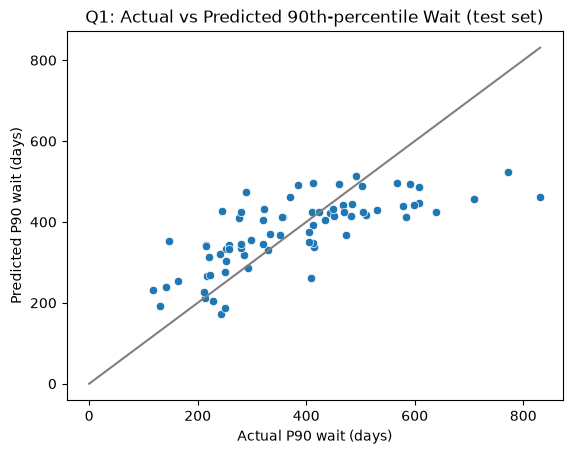

In [11]:
# Chart of actual vs predicted waits on the test set.
# Points close to the diagonal line are good predictions.
sns.scatterplot(x=y_test,y=y_pred)
sns.lineplot(x=[0,y_test.max()],y=[0,y_test.max()],color='grey')
plt.title('Q1: Actual vs Predicted 90th-percentile Wait (test set)')
plt.xlabel('Actual P90 wait (days)')
plt.ylabel('Predicted P90 wait (days)')
plt.show()

In [12]:
# Coefficients: how much the predicted wait changes when a feature goes up by 1,
# holding the other features the same.
# Example: a coefficient of -0.2 for Volume_per_100k means 1 extra procedure per 100,000 people
# goes with a 0.2-day shorter wait. Procedure coefficients are compared with hip replacement.
# Note: Pct_65plus and Median_Age both measure ageing and move together, so read them as a pair
# rather than one at a time. The intercept is a large number because Year is around 2020;
# it has no business meaning on its own.
coef=pd.DataFrame({'Feature':features_q1,'Coefficient':lr.coef_})
print("Intercept:",round(lr.intercept_,1))
coef

Intercept: -9973.6


,Feature,Coefficient
0,Volume_per_100k,-0.188081
1,Pct_65plus,26.782892
2,Median_Age,-16.292892
3,COVID_Flag,35.117790
4,Year,5.217779
5,is_knee,73.432059
6,is_cataract,-41.398003


In [13]:
# Is Alberta waiting longer than the model expects?
# Predict every Alberta row, then compare: residual = actual wait - predicted wait.
# Positive residual = Alberta waits LONGER than a province with its capacity and ageing "should";
# negative residual = shorter than expected.
alberta=q1[q1['Province']=='Alberta']
alberta['Predicted_P90']=lr.predict(alberta[features_q1])
alberta['Residual_P90']=alberta['P90_Days']-alberta['Predicted_P90']

alberta.groupby('Indicator')[['P90_Days','Predicted_P90','Residual_P90']].mean().round(1)

,P90_Days,Predicted_P90,Residual_P90
Indicator,,,
Cataract Surgery,286.7,240.5,46.2
Hip Replacement,345.7,328.1,17.6
Knee Replacement,401.9,397.2,4.7


In [14]:
# The same comparison for every province, averaged over all procedures and years,
# to see where Alberta ranks among the provinces.
q1['Predicted_P90']=lr.predict(q1[features_q1])
q1['Residual_P90']=q1['P90_Days']-q1['Predicted_P90']

q1.groupby('Province')['Residual_P90'].mean().sort_values(ascending=False).round(1)

Province
Manitoba                     71.0
Nova Scotia                  69.8
New Brunswick                29.1
Prince Edward Island         27.8
Alberta                      22.8
Saskatchewan                 21.3
Newfoundland and Labrador    -5.1
British Columbia            -60.1
Quebec                      -78.0
Ontario                     -91.5
Name: Residual_P90, dtype: float64

In [15]:
# Alberta's extra wait (actual - expected) by year, and by year and procedure.
# Also: how many of Alberta's rows were in the test set (the rest were used for training).
ab=q1[q1['Province']=='Alberta']
print("Alberta rows in the test set:",ab.index.isin(X_test.index).sum(),"of",len(ab))
print(ab.groupby('Year')['Residual_P90'].mean().round(1))
pd.crosstab(ab['Year'],ab['Indicator'],values=ab['Residual_P90'],aggfunc='mean').round(0)

Alberta rows in the test set: 8 of 30
Year
2016    -21.9
2017     -8.3
2018     11.8
2019     20.9
2020     49.4
2021     15.0
2022    108.7
2023     68.4
2024    -31.2
2025     15.5
Name: Residual_P90, dtype: float64


Indicator,Cataract Surgery,Hip Replacement,Knee Replacement
Year,,,
2016,63.0,-47.0,-81.0
2017,66.0,-26.0,-66.0
2018,116.0,-22.0,-58.0
2019,145.0,-27.0,-55.0
2020,123.0,26.0,-1.0
2021,0.0,28.0,17.0
2022,-1.0,155.0,171.0
2023,-21.0,106.0,120.0
2024,-20.0,-48.0,-26.0


# Q2 — K-Nearest Neighbors (classification)
**Business question:** Can we predict whether a province meets or beats Canada's performance on a procedure in a given year?
**Target:** `Meets_Canada` (1 = same or higher share of patients treated on time than Canada, 0 = lower).

In [16]:
# Features: the same capacity, ageing, time and procedure columns as Q1.
# The wait time columns are NOT used: they are measured from the same patients as the target,
# so they would give the answer away instead of predicting it.
# For KNN all five procedure columns can be kept (KNN measures distance, it does not fit an equation).
features_q2=['Volume_per_100k','Pct_65plus','Median_Age','COVID_Flag','Year',
             'is_hip','is_knee','is_cataract','is_radiation','is_hip_fracture']
target_q2='Meets_Canada'

# Remove rows with missing values (Quebec hip fracture repair).
q2=data.dropna(subset=features_q2+[target_q2])
print(q2.shape)

X=q2[features_q2]
y=q2[target_q2].astype(int)

# How balanced is the target? (share of 0s and 1s)
y.value_counts(normalize=True)

(490, 18)


Meets_Canada
0    0.602041
1    0.397959
Name: proportion, dtype: float64

In [17]:
# Test design: 75% training, 25% test, same random_state as Q1.
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123)
print(X_train.shape, X_test.shape)

(367, 10) (123, 10)


In [18]:
# Scale the features (standardize), as recommended for KNN.
# KNN compares rows by distance. Without scaling, a column with big numbers (Year, about 2020)
# would outweigh a column with small numbers (COVID_Flag, 0 or 1).
# Standardizing = (value - average) / standard deviation, so every column is on the same scale.
# The average and standard deviation come from the TRAINING set only, and are reused for the
# test set, so the test set stays truly unseen.
train_mean=X_train.mean()
train_std=X_train.std()

X_train_s=(X_train-train_mean)/train_std
X_test_s=(X_test-train_mean)/train_std
X_train_s.describe().round(2)

,Volume_per_100k,Pct_65plus,Median_Age,COVID_Flag,Year,is_hip,is_knee,is_cataract,is_radiation,is_hip_fracture
count,367.00,367.00,367.00,367.00,367.00,367.00,367.0,367.00,367.00,367.00
mean,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.0,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00
min,-0.76,-2.43,-1.65,-0.49,-1.56,-0.51,-0.5,-0.49,-0.53,-0.47
25%,-0.61,-0.74,-1.10,-0.49,-0.86,-0.51,-0.5,-0.49,-0.53,-0.47
50%,-0.34,0.03,0.02,-0.49,-0.16,-0.51,-0.5,-0.49,-0.53,-0.47
75%,-0.04,0.66,0.95,-0.49,0.89,-0.51,-0.5,-0.49,-0.53,-0.47
max,4.62,2.20,1.87,2.02,1.59,1.97,2.0,2.02,1.89,2.11


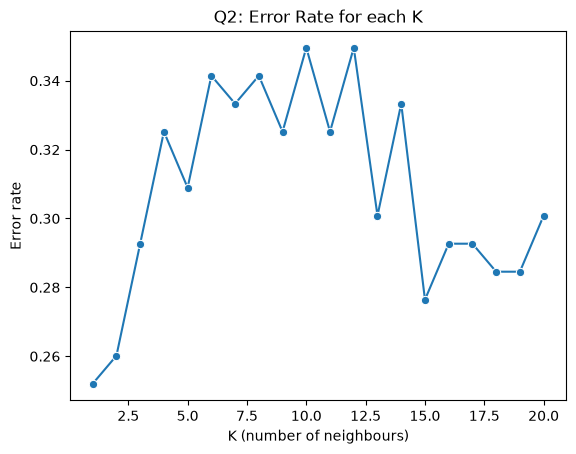

In [19]:
# Choose K (the number of neighbours that "vote"):
# try K = 1 to 20 and record the error rate (share of wrong predictions) for each.
# Small K can overfit (too detailed); large K can underfit (too smooth).
k_values=list(range(1,21))
error_rates=[]

for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s,y_train)
    pred=knn.predict(X_test_s)
    error_rates.append(1-accuracy_score(y_test,pred))

sns.lineplot(x=k_values,y=error_rates,marker='o')
plt.title('Q2: Error Rate for each K')
plt.xlabel('K (number of neighbours)')
plt.ylabel('Error rate')
plt.show()

In [20]:
# Pick the smallest K with the lowest error rate.
# Note: a very small K (such as 1) follows individual rows closely and can overfit,
# so check the chart: if several K values have similar error rates, the result is stable.
best_k=k_values[error_rates.index(min(error_rates))]
print("Best K:",best_k,"  error rate:",round(min(error_rates),3))

Best K: 1   error rate: 0.252


In [21]:
# Build the final KNN model with the best K and predict the test set.
knn=KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s,y_train)
y_pred=knn.predict(X_test_s)

# Assess the model:
# Accuracy  = share of all predictions that were right.
# Precision = of the rows predicted "meets Canada", the share that really did.
# Recall    = of the rows that really met Canada, the share the model found.
# F-score   = a single score that balances precision and recall.
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision_score(y_test,y_pred):.3f}")
print(f"Recall   : {recall_score(y_test,y_pred):.3f}")
print(f"F-score  : {f1_score(y_test,y_pred):.3f}")

# Baseline: always guessing the most common answer in the test set.
baseline_acc=y_test.value_counts(normalize=True).max()
print(f"Baseline accuracy (always guess the most common class): {baseline_acc:.3f}")
print("Beats baseline:",accuracy>baseline_acc)

Accuracy : 0.748
Precision: 0.761
Recall   : 0.636
F-score  : 0.693
Baseline accuracy (always guess the most common class): 0.553
Beats baseline: True


In [22]:
# Cross-table of actual answers (rows, Meets_Canada) vs predicted answers (columns, col_0).
# The diagonal (0-0 and 1-1) are the correct predictions; the other two cells are mistakes.
pd.crosstab(y_test,y_pred)

col_0,0,1
Meets_Canada,,
0,57,11
1,20,35


In [23]:
# Use the model for Alberta's latest year (2025): does the model expect Alberta to meet Canada,
# and what actually happened? The rows are scaled with the same training average and spread.
ab25=q2[(q2['Province']=='Alberta') & (q2['Year']==2025)]
ab25_s=(ab25[features_q2]-train_mean)/train_std

result=ab25[['Indicator','Pct_Within_Benchmark','Gap_Pct_vs_Canada','Meets_Canada']]
result['KNN_Predicted']=knn.predict(ab25_s)
result

,Indicator,Pct_Within_Benchmark,Gap_Pct_vs_Canada,Meets_Canada,KNN_Predicted
9,Cataract Surgery,66.000000,-3.677240,0.0,0
19,Hip Fracture Repair,87.390351,3.255593,1.0,1
29,Hip Replacement,63.000000,-6.198609,0.0,0
39,Knee Replacement,52.500000,-10.299446,0.0,0
49,Radiation Therapy,97.000000,1.590823,1.0,1


In [24]:
# For CRISP-DM document (Q2).
# Most common answer in the training rows (the baseline guess is the same as in the test rows).
print("Training rows by answer (0 = below Canada, 1 = meets Canada):")
print(y_train.value_counts())

# Which of Alberta's 2025 rows were in the test set (unseen) and which were training rows.
result['In_Test_Set']=ab25.index.isin(X_test.index)
print(result[['Indicator','Meets_Canada','KNN_Predicted','In_Test_Set']])

# All of Alberta's test rows (2016 to 2025): how many did the model predict correctly?
ab_test=q2[(q2['Province']=='Alberta') & (q2.index.isin(X_test.index))]
ab_pred=knn.predict((ab_test[features_q2]-train_mean)/train_std)
print("Alberta rows in the test set:",len(ab_test),"  predicted correctly:",(ab_pred==ab_test['Meets_Canada']).sum())

Training rows by answer (0 = below Canada, 1 = meets Canada):
Meets_Canada
0    227
1    140
Name: count, dtype: int64
              Indicator  Meets_Canada  KNN_Predicted  In_Test_Set
9      Cataract Surgery           0.0              0         True
19  Hip Fracture Repair           1.0              1        False
29      Hip Replacement           0.0              0        False
39     Knee Replacement           0.0              0        False
49    Radiation Therapy           1.0              1         True
Alberta rows in the test set: 16   predicted correctly: 15


# Q3 — K-Means Clustering
**Business question:** Which provinces share a similar profile of access to care and demographic pressure, and where does Alberta sit relative to Canada?

In [25]:
# Build one profile row per province (average over 2016-2025):
# - share of patients treated within the benchmark for 4 procedures
#   (hip fracture repair is left out because Quebec does not report it),
# - share of the population aged 65+, and median age.
# pd.crosstab with values= and aggfunc='mean' makes a table of averages:
# one row per province, one column per procedure.
q3_proc=['Hip Replacement','Knee Replacement','Cataract Surgery','Radiation Therapy']
q3=data[data['Indicator'].isin(q3_proc)]

profile=pd.crosstab(q3['Province'],q3['Indicator'],values=q3['Pct_Within_Benchmark'],aggfunc='mean')

# Add the two ageing columns (province averages); they line up by province name.
profile['Pct_65plus']=data.groupby('Province')['Pct_65plus'].mean()
profile['Median_Age']=data.groupby('Province')['Median_Age'].mean()
profile.round(1)

Indicator,Cataract Surgery,Hip Replacement,Knee Replacement,Radiation Therapy,Pct_65plus,Median_Age
Province,,,,,,
Alberta,56.0,63.0,55.1,98.0,13.9,37.5
British Columbia,72.1,65.0,56.2,87.8,19.0,41.7
Manitoba,40.8,52.8,39.3,99.4,16.1,37.6
New Brunswick,64.5,47.8,41.3,93.9,21.9,45.6
Newfoundland and Labrador,60.2,61.6,49.1,91.4,22.5,47.3
Nova Scotia,62.9,56.3,45.9,89.7,21.2,44.6
Ontario,63.8,79.3,75.1,98.2,17.6,40.4
Prince Edward Island,40.7,51.2,34.3,97.0,20.1,42.8
Quebec,72.8,63.1,54.6,97.0,19.8,42.6


In [26]:
# Canada's profile, built the same way, so it can be placed among the clusters later.
# Canada is NOT used to build the clusters: it is the benchmark, not a comparison case.
# Canada's values come from the star schema tables saved in Data Preparation.
fact=pd.read_csv(cleaned_path+'Fact_WaitTimes.csv')
geo=pd.read_csv(cleaned_path+'Dim_Geography.csv')
proc=pd.read_csv(cleaned_path+'Dim_Procedure.csv')
full=pd.merge(fact,geo,on='GeoKey')
full=pd.merge(full,proc,on='ProcedureKey')

ca=full[(full['Province']=='Canada') & (full['Indicator'].isin(q3_proc))]
canada_profile=pd.crosstab(ca['Province'],ca['Indicator'],values=ca['Pct_Within_Benchmark'],aggfunc='mean')
canada_profile['Pct_65plus']=full[full['Province']=='Canada']['Pct_65plus'].mean()
canada_profile['Median_Age']=full[full['Province']=='Canada']['Median_Age'].mean()
canada_profile.round(1)

Indicator,Cataract Surgery,Hip Replacement,Knee Replacement,Radiation Therapy,Pct_65plus,Median_Age
Province,,,,,,
Canada,66.8,68.6,61.9,96.1,18.0,40.7


In [27]:
# Standardize the profile columns (same reason as Q2: K-Means uses distance,
# so every column must be on the same scale). Canada uses the provinces' average and spread.
p_mean=profile.mean()
p_std=profile.std()
profile_s=(profile-p_mean)/p_std
canada_s=(canada_profile-p_mean)/p_std

   k  Inertia  Silhouette
0  2   33.855       0.273
1  3   21.254       0.269
2  4   14.863       0.265
3  5    9.587       0.224
4  6    6.840       0.185


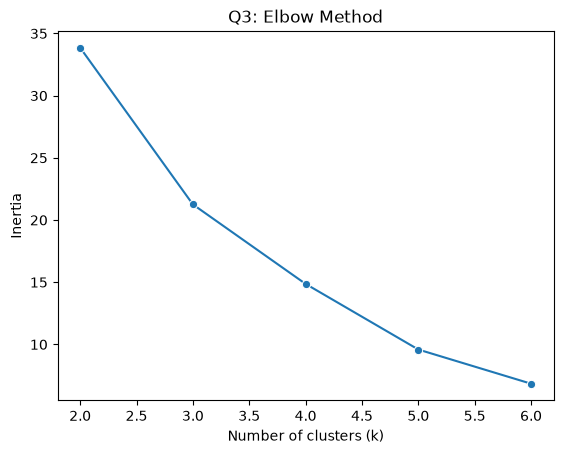

In [28]:
# Choose the number of clusters (k) with the elbow method and the silhouette score.
# Inertia: how spread out the points are inside their clusters (lower = tighter clusters).
#          Look for the "elbow" where adding more clusters stops helping much.
# Silhouette: from -1 to 1, how well each province fits its own cluster compared with the
#          nearest other cluster (higher = clearer groups).
# With only 10 provinces, k is tried from 2 to 6.
k_range=list(range(2,7))
inertias=[]
silhouettes=[]

for k in k_range:
    km=KMeans(n_clusters=k,random_state=123,n_init=10)
    labels=km.fit_predict(profile_s)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(profile_s,labels))

print(pd.DataFrame({'k':k_range,'Inertia':inertias,'Silhouette':silhouettes}).round(3))

sns.lineplot(x=k_range,y=inertias,marker='o')
plt.title('Q3: Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.show()

In [29]:
# Pick k with the highest silhouette score (clearest grouping), then build the final model.
# n_init=10 runs K-Means 10 times from different starting points and keeps the best result.
best_k3=k_range[silhouettes.index(max(silhouettes))]
print("Chosen k:",best_k3,"  silhouette:",round(max(silhouettes),3))

# Success criterion from Business Understanding: silhouette >= 0.30.
# A value a little below 0.30 means the groups exist but overlap somewhat, so the clusters
# should be read as broad groupings rather than sharply separated types.
print("Silhouette >= 0.30:",max(silhouettes)>=0.30)

kmeans=KMeans(n_clusters=best_k3,random_state=123,n_init=10)
profile['Cluster']=kmeans.fit_predict(profile_s)

# Place Canada: which cluster is Canada's profile closest to?
canada_cluster=kmeans.predict(canada_s)[0]
print("Canada's profile falls in cluster:",canada_cluster)
print("Alberta is in cluster:",profile.loc['Alberta','Cluster'])

Chosen k: 2   silhouette: 0.273
Silhouette >= 0.30: False
Canada's profile falls in cluster: 0
Alberta is in cluster: 1


In [30]:
# Which provinces are in each cluster?
profile[['Cluster']].sort_values(by='Cluster')

Indicator,Cluster
Province,
British Columbia,0
New Brunswick,0
Nova Scotia,0
Newfoundland and Labrador,0
Ontario,0
Quebec,0
Manitoba,1
Alberta,1
Prince Edward Island,1


In [31]:
# Describe each cluster by its average profile, so the groups can be explained in business terms.
cluster_summary=profile.groupby('Cluster').mean().round(1)
cluster_summary

Indicator,Cataract Surgery,Hip Replacement,Knee Replacement,Radiation Therapy,Pct_65plus,Median_Age
Cluster,,,,,,
0,66.1,62.2,53.7,93.0,20.3,43.7
1,50.8,55.0,43.0,97.9,16.7,38.9


In [32]:
# Revised parameter check (CRISP-DM Modeling step).
# Pct_65plus and Median_Age measure the same thing (ageing), so age is counted twice.
print("Correlation between Pct_65plus and Median_Age:",round(profile['Pct_65plus'].corr(profile['Median_Age']),2))

# Sensitivity check: cluster again using ONLY the 4 access columns (share treated within benchmark).
access=profile[q3_proc]
access_s=(access-access.mean())/access.std()

access_sil=[]
for k in k_range:
    km=KMeans(n_clusters=k,random_state=123,n_init=10)
    access_sil.append(silhouette_score(access_s,km.fit_predict(access_s)))
print("Silhouette (access only):",[round(x,3) for x in access_sil])

# Which provinces end up together with 2 groups when only access is used?
km_access=KMeans(n_clusters=2,random_state=123,n_init=10)
access['Access_Group']=km_access.fit_predict(access_s)
access[['Access_Group']].sort_values(by='Access_Group')

Correlation between Pct_65plus and Median_Age: 0.97
Silhouette (access only): [0.352, 0.347, 0.305, 0.378, 0.361]


Indicator,Access_Group
Province,
Alberta,0
British Columbia,0
New Brunswick,0
Newfoundland and Labrador,0
Ontario,0
Nova Scotia,0
Saskatchewan,0
Quebec,0
Prince Edward Island,1


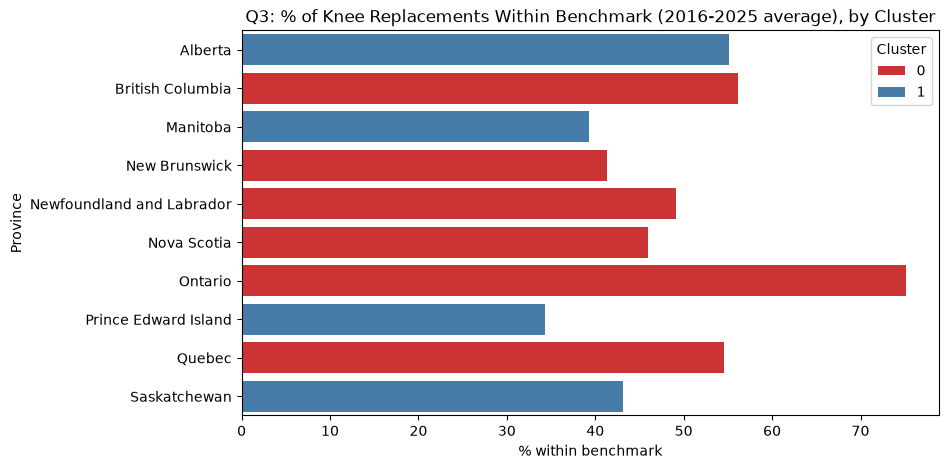

Canada (benchmark): 61.9 %


In [33]:
# Chart: knee replacement access for each province, coloured by cluster.
# Canada's value is printed below the chart for reference.
# The bars are horizontal (province names on the y axis) so the long names do not overlap.
plt.figure(figsize=(9,5))
sns.barplot(x=profile['Knee Replacement'],y=profile.index,hue=profile['Cluster'],dodge=False,palette='Set1')
plt.title('Q3: % of Knee Replacements Within Benchmark (2016-2025 average), by Cluster')
plt.xlabel('% within benchmark')
plt.ylabel('Province')
plt.show()

print("Canada (benchmark):",round(canada_profile['Knee Replacement'].iloc[0],1),"%")

# Save model results for Power BI

In [34]:
# Save the model results so Power BI can show them next to the data.
# Q1 + Q2: one row per province, procedure and year, with the regression prediction and residual
# and the KNN prediction. Rows with missing inputs (Quebec) are left blank.
out=data[['Province','Indicator','Year']]
out=pd.merge(out,q1[['Province','Indicator','Year','Predicted_P90','Residual_P90']],
             on=['Province','Indicator','Year'],how='left')

q2_all=q2[['Province','Indicator','Year']]
q2_all['KNN_Predicted']=knn.predict((q2[features_q2]-train_mean)/train_std)
out=pd.merge(out,q2_all,on=['Province','Indicator','Year'],how='left')

# Swap names for the star schema keys, so the table links to the dimension tables in Power BI.
year=pd.read_csv(cleaned_path+'Dim_Year.csv')
out=pd.merge(out,geo[['Province','GeoKey']],on='Province')
out=pd.merge(out,proc[['Indicator','ProcedureKey']],on='Indicator')
out=pd.merge(out,year[['Year','YearKey']],on='Year')
out=out[['GeoKey','ProcedureKey','YearKey','Predicted_P90','Residual_P90','KNN_Predicted']]
out.to_csv(cleaned_path+'Model_Predictions.csv',index=False)
print(out.shape)

(500, 6)


In [35]:
# Q3: one row per province with its cluster, linked to Dim_Geography by GeoKey.
clusters=pd.DataFrame({'Province':profile.index,'Cluster':profile['Cluster'].values})
clusters=pd.merge(clusters,geo[['Province','GeoKey']],on='Province')
clusters=clusters[['GeoKey','Province','Cluster']]
clusters.to_csv(cleaned_path+'Model_Clusters.csv',index=False)
clusters

,GeoKey,Province,Cluster
0,2,Alberta,1
1,3,British Columbia,0
2,4,Manitoba,1
3,5,New Brunswick,0
4,6,Newfoundland and Labrador,0
5,7,Nova Scotia,0
6,8,Ontario,0
7,9,Prince Edward Island,1
8,10,Quebec,0
9,11,Saskatchewan,1
